# Catalogue quality challenge: a team walkthrough

We want to spot listings with an injected catalogue error. The useful question turned out to be:

**Given the product in the text, how plausible are the category, quantity, price and weight?**

This notebook walks through the working approach with the code next to each explanation.
It keeps the modelling and validation from the full pipeline, while leaving out the command-line interface,
model packaging and most reporting utilities. The displayed results come from executing these cells.

The target is `0` for **no controlled corruption** and `1` for **one controlled corruption**.
A target of 0 still allows missing values, discounts and legitimate alternative categories.

**Reading route:** data → facts from text → expected attributes → deviations → honest validation → results → submission.

**Running it:** keep this notebook in `notebooks/` inside the project, use the environment from
`requirements-notebook.txt`, and choose **Restart Kernel and Run All Cells**. It trains on CPU. The notebook
does not need the `catalogue_quality` Python package: the essential functions are shown here.
Original data and saved production models are preserved. Notebook-generated files go to
`outputs/notebook_walkthrough/` and are refreshed when the notebook is rerun.

## 1. Load the data

Each row is one offer. We have structured fields such as category and weight, plus a title and description.
The test file has the same inputs but no target. The sample submission tells us the required output order.

The checks below catch overlapping IDs, overlapping sellers and invalid numeric values before training.

In [1]:
%matplotlib inline
import hashlib
import json
import re
import unicodedata
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from catboost import CatBoostClassifier
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Ridge
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (8, 3.6), "figure.dpi": 115, "font.size": 11})
pd.set_option("display.max_colwidth", 90)
TEAL, ORANGE, NAVY = "#087f8c", "#e68a2e", "#243b53"

# Works when Jupyter starts in either the project folder or notebooks/.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "data/dsc-pjatk-catalogue-quality-challenge/train.csv").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from the project containing data/ and requirements.txt.")
DATA = ROOT / "data/dsc-pjatk-catalogue-quality-challenge"

In [2]:
train = pd.read_csv(DATA / "train.csv")
test = pd.read_csv(DATA / "test.csv")
sample = pd.read_csv(DATA / "sample_submission.csv")

assert train.id.is_unique and test.id.is_unique
assert set(train.id).isdisjoint(test.id)
assert set(train.seller_id).isdisjoint(test.seller_id)
assert sample.id.tolist() == test.id.tolist()
assert train.target.notna().all() and train.target.isin([0, 1]).all()
assert "target" not in test.columns
for frame in [train, test]:
    for column in ["price_pln", "shipping_weight_kg", "pack_size"]:
        observed = frame[column].dropna()
        assert np.isfinite(observed).all() and observed.gt(0).all()

display(pd.DataFrame({
    "split": ["train", "test"], "listings": [len(train), len(test)],
    "sellers": [train.seller_id.nunique(), test.seller_id.nunique()],
}))
display(train[["title", "description", "declared_category", "pack_size", "target"]].head(3))

,split,listings,sellers
0,train,16000,800
1,test,10000,500


,title,description,declared_category,pack_size,target
0,recording mic support — pack of one — Mira A513,Pack of one main items. Microphone stand by Mira. Variant: standard. For listening at ...,audio,1.0,1
1,in-ear cable headphones — quantity 2 — Noro E315,Included main items: 2. Wired earbuds by Noro. Variant: compact. For listening at home...,computers,2.0,1
2,Tenso digital food balance / standard / quantity 1,Included main items: 1. Kitchen scale by Tenso. Variant: standard. For food preparatio...,kitchen,1.0,0


About 17% of the training rows are positive, so accuracy alone would be misleading: predicting 0 for
everything already gets about 83% accuracy. We use **ROC-AUC** to evaluate how well the model ranks
corrupted rows above other rows, and **Average Precision** to check how well it retrieves the positive class.
Neither metric is a percentage of correctly classified rows.

Missing values are part of the inputs. We preserve them as unknowns and retain missingness information.
We do not label a row as corrupted simply because something is absent.

,listings
target,
No controlled corruption,13279
Controlled corruption,2721


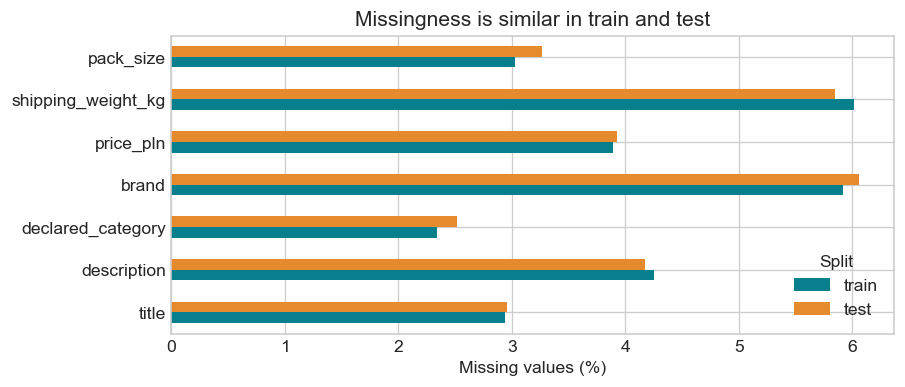

In [3]:
display(train.target.value_counts().rename(index={0: "No controlled corruption", 1: "Controlled corruption"})
        .to_frame("listings"))
missing = pd.DataFrame({"train": train.drop(columns="target").isna().mean(),
                        "test": test.isna().mean()}).mul(100)
missing = missing.loc[missing.max(axis=1).gt(0)]
ax = missing.plot.barh(color=[TEAL, ORANGE], figsize=(8, 3.5))
ax.set(xlabel="Missing values (%)", ylabel="", title="Missingness is similar in train and test")
ax.legend(title="Split")
plt.tight_layout()
plt.show()

## 2. Turn the text into a few useful facts

These descriptions follow a small set of templates. For example, we can read
`Wired earbuds by Noro. Variant: compact. Included main items: 2.` as three facts:

| Fact | Extracted value |
|---|---|
| Product phrase | wired earbuds |
| Variant | compact |
| Main-item quantity | 2 |

We normalize case and whitespace, then use regular expressions to recognize the known templates.
This is a small, task-specific form of NLP. We keep the raw text in the original tables for inspection.
The final model uses extracted facts rather than raw-text TF-IDF vectors.

Quantity needs context. **“3 pcs of free accessories” does not mean three main items.**
We search for main-item phrases first and use the title when the description gives no main quantity.

In [4]:
MISSING = "__missing__"
CATS = ["declared_category", "brand", "condition", "product", "variant"]
NUMS = ["price_pln", "shipping_weight_kg", "pack_size"]
WORDS = {"one": 1, "two": 2, "three": 3, "five": 5}
COUNT = r"(\d+|one|two|three|five)"

def normalize(value):
    if pd.isna(value):
        return ""
    return re.sub(r"\s+", " ", unicodedata.normalize("NFKC", str(value)).lower()).strip()

def main_quantity(text, description=False):
    patterns = [
        rf"included main items:\s*{COUNT}", rf"package contains\s+{COUNT}\s+pcs",
        rf"bundle quantity:\s*{COUNT}\s+units", rf"sold as a\s+{COUNT}-pack",
        rf"pack of\s+{COUNT}\s+main items", rf"{COUNT}\s+individually boxed main items",
    ] if description else [
        rf"quantity\s+{COUNT}\b", rf"pack of\s+{COUNT}\b",
        rf"\b{COUNT}\s*(?:-pack|pcs|units|main items)\b",
    ]
    for pattern in patterns:
        match = re.search(pattern, normalize(text))
        if match:
            token = match.group(1)
            value = WORDS[token] if token in WORDS else int(token)
            return float(value) if value > 0 else np.nan
    return np.nan

In [5]:
examples = [
    "Also includes 3 pcs of free accessory pieces. Included main items: 1.",
    "Five individually boxed main items.",
    "Also includes 3 pcs of free accessory pieces.",
]
display(pd.DataFrame({"description": examples,
                      "main_items": [main_quantity(s, description=True) for s in examples]}))

,description,main_items
0,Also includes 3 pcs of free accessory pieces. Included main items: 1.,1.0
1,Five individually boxed main items.,5.0
2,Also includes 3 pcs of free accessory pieces.,NaN


The next function puts the extracted facts next to the structured inputs. It also adds:

- The difference between the text quantity and `pack_size`.
- Price and weight per declared item, and per item counted in the text.
- Log values, which make multiplicative differences easier to model.
- A few context flags, including promotions, accessories and numeric missingness.

We retain promotion wording because it can explain a legitimate low price. Unknown products and
categories stay unknown. Seller IDs and listing IDs are never model features.

In [6]:
def make_features(df):
    x = df[["declared_category", "brand", "condition", *NUMS]].copy()
    title, desc = df.title.map(normalize), df.description.map(normalize)
    x["product"] = desc.str.extract(
        r"(?:^|\. )([^.]*) by (?:aster|mira|noro|tenso|velto)\.", expand=False)
    variant = desc.str.extract(r"variant:\s*(\w+)", expand=False).astype("string")
    fallback = title.str.extract(r"\b(standard|compact|large)\b", expand=False).astype("string")
    x["variant"] = variant.fillna(fallback)
    x["desc_quantity"] = desc.map(lambda s: main_quantity(s, description=True))
    x["title_quantity"] = title.map(main_quantity)
    x["main_quantity"] = x.desc_quantity.fillna(x.title_quantity)
    x["quantity_difference"] = x.pack_size - x.main_quantity
    x["title_desc_quantity_difference"] = x.title_quantity - x.desc_quantity
    x["clearance"] = desc.str.contains("clearance promotion", regex=False).astype(int)
    x["accessory"] = desc.str.contains("free accessory", regex=False).astype(int)
    x["title_length"], x["description_length"] = title.str.len(), desc.str.len()
    for col in NUMS:
        x[col + "_missing"] = df[col].isna().astype(int)
        x["log_" + col] = np.log(df[col])
    for col in ["price_pln", "shipping_weight_kg"]:
        x[col + "_per_declared_item"] = df[col] / df.pack_size
        x[col + "_per_text_item"] = df[col] / x.main_quantity
    for col in CATS:
        x[col] = x[col].fillna(MISSING).astype(str)
    return x.replace([np.inf, -np.inf], np.nan)

X, X_test = make_features(train), make_features(test)
y = train.target.to_numpy()
assert set(["id", "seller_id", "target"]).isdisjoint(X.columns)

In [7]:
display(pd.Series({
    "Descriptions with a parsed product (%)": X['product'].ne(MISSING).mean() * 100,
    "Distinct product phrases": X.loc[X['product'].ne(MISSING), 'product'].nunique(),
    "Listings with a parsed main quantity (%)": X.main_quantity.notna().mean() * 100,
}).to_frame("value").round(3))
display(X[["product", "variant", "main_quantity", "pack_size", "quantity_difference"]].head(6))

,value
Descriptions with a parsed product (%),95.750
Distinct product phrases,180.000
Listings with a parsed main quantity (%),99.938


,product,variant,main_quantity,pack_size,quantity_difference
0,microphone stand,standard,1.0,1.0,0.0
1,wired earbuds,compact,2.0,2.0,0.0
2,kitchen scale,standard,1.0,1.0,0.0
3,cat tray cleaning shovel,standard,5.0,5.0,0.0
4,notebook protective pouch,standard,5.0,5.0,0.0
5,bluetooth speaker,standard,2.0,2.0,0.0


## 3. Learn what categories are normal for each product

A universal rule such as “headphones belong to audio” is too strict for this catalogue.
Some uncorrupted headphone listings legitimately use computers. We learn those conventions from
rows with `target=0` instead.

For product `p` and declared category `c`, we calculate:

```text
P(category=c | product=p) = (reference count for p,c + 1) / (all reference counts for p + K)
category_surprisal = -log(P(category=c | product=p))
```

`K` is the number of categories in the reference table. Adding 1 prevents a previously unseen
pair from receiving zero probability and infinite surprise. A high score means the pairing is unusual;
it is not directly the probability of corruption.

**The next cell is an illustration using all target-0 rows. Its table is never used as a training feature.**
The actual models below build fresh reference tables inside each training partition.

In [8]:
illustration = X.loc[train.target.eq(0) & X['product'].ne(MISSING)
                      & X.declared_category.ne(MISSING)]
illustration_counts = pd.crosstab(illustration['product'], illustration.declared_category)
headphones = illustration_counts.loc["wireless headphones"]
rows = []
for category in ["audio", "computers", "pets"]:
    count = int(headphones.get(category, 0))
    probability = (count + 1) / (headphones.sum() + len(illustration_counts.columns))
    rows.append({"declared_category": category, "reference_count": count,
                 "probability": probability, "surprisal": -np.log(probability)})
display(pd.DataFrame(rows).round(3))

,declared_category,reference_count,probability,surprisal
0,audio,88,0.742,0.299
1,computers,23,0.200,1.609
2,pets,0,0.008,4.787


## 4. Learn expected prices and weights

A price of PLN 200 means different things for an SSD, a mug and a pack of five items.
We fit two **ridge regressions** on rows without controlled corruption: one predicts log price,
and the other predicts log shipping weight. Ridge is a linear model with regularization to keep
its estimates stable.

Inputs are product phrase, variant, brand, condition, text quantity and promotion status.
Categorical inputs are one-hot encoded for these regressions. CatBoost later handles its categorical
inputs directly.

We exclude the observed price from the price predictor, and the observed weight from the weight predictor.
We also use the quantity extracted from text rather than the potentially corrupted `pack_size`.
The model has to estimate what the value should look like from the surrounding information.

In [9]:
REF_CATS = ["product", "variant", "brand", "condition"]

def reference_inputs(x):
    inputs = x[REF_CATS + ["clearance"]].copy()
    inputs["log_main_quantity"] = np.log(x.main_quantity.fillna(1))
    return inputs

def fit_reference(x, labels):
    clean = x.iloc[np.flatnonzero(np.asarray(labels) == 0)]
    regressors = {}
    for column in ["price_pln", "shipping_weight_kg"]:
        observed = clean.loc[clean[column].notna()]
        preprocessing = ColumnTransformer([
            ("categories", OneHotEncoder(handle_unknown="ignore"), REF_CATS),
            ("numbers", "passthrough", ["clearance", "log_main_quantity"]),
        ])
        regression = make_pipeline(preprocessing, Ridge(alpha=2, solver="lsqr"))
        regression.fit(reference_inputs(observed), np.log(observed[column]))
        regressors[column] = regression
    known = clean.loc[clean['product'].ne(MISSING) & clean.declared_category.ne(MISSING)]
    counts = pd.crosstab(known['product'], known.declared_category)
    return regressors, counts

We turn each estimated value into three features: the expected log value, the signed deviation and
the absolute deviation. The signed deviation tells us the direction; the absolute deviation tells us the size.

```text
price residual = log(observed price) - predicted log price
               = log(observed price / expected price)
```

An observed price of 200 against an expected price of 100 gives a residual of about +0.693.
A price of 50 gives about -0.693: both are a factor of two away.

Category surprisal joins these numeric deviations. When the product or declared category is unknown,
its category score remains missing. Before the classifier, numeric missing values use `-999` as a
recognizable placeholder; categorical missing values use `__missing__`. The placeholder is not a measured value.
If text quantity is unavailable, the reference regressions use 1 as a fallback; the classifier still sees
that the parsed quantity is missing.

In [10]:
def reference_features(x, reference):
    regressors, counts = reference
    features = pd.DataFrame(index=x.index)
    for column, regression in regressors.items():
        expected = regression.predict(reference_inputs(x))
        residual = np.log(x[column]) - expected
        features[column + "_expected_log"] = expected
        features[column + "_residual"] = residual
        features[column + "_abs_residual"] = np.abs(residual)
    probabilities = []
    for product, category in zip(x['product'], x.declared_category):
        if product not in counts.index or category == MISSING:
            probabilities.append(np.nan)
        else:
            row = counts.loc[product]
            probabilities.append((row.get(category, 0) + 1) / (row.sum() + len(counts.columns)))
    features["category_surprisal"] = -np.log(probabilities)
    return features

def classifier_inputs(features):
    result = features.copy()
    for column in result:
        if column in CATS:
            result[column] = result[column].fillna(MISSING).astype(str)
        else:
            result[column] = result[column].replace([np.inf, -np.inf], np.nan).fillna(-999.)
    return result

## 5. Keep sellers out of their own validation data

Test sellers do not appear in training. Our validation needs to imitate that:
all listings from a seller stay together in one of five **outer folds**.

There is a second leakage risk. Reference models use `target=0` rows. If we calculated training
features using a reference model that had already seen the same row, its label could influence its own
features. We avoid that with three **inner seller folds**.

```text
For one outer fold:
  Outer training sellers → split into 3 inner groups
  Each inner group gets reference features learned from the other groups
  Those features + outer training labels → train CatBoost

  All outer training sellers → fit the reference models for validation and test
  Held-out outer sellers → reference features → CatBoost predictions → score
```

Using known training labels to select reference rows is allowed. Held-out labels are used only to
measure the resulting predictions. We do not use them for early stopping or hyperparameter selection.
The five-fold assignment below matches the supplied baseline.

In [11]:
N_FOLDS, INNER_FOLDS, SEED = 5, 3, 42
fold_id = np.array([
    int(hashlib.sha256(f"{SEED}:{seller}".encode()).hexdigest()[:16], 16) % N_FOLDS
    for seller in train.seller_id
])
fold_table = train.assign(fold=fold_id + 1).groupby("fold").agg(
    listings=("id", "size"), sellers=("seller_id", "nunique"), positive_rate=("target", "mean"))
display(fold_table.round(3))

def inner_reference_features(x, labels, sellers):
    pieces = []
    labels, sellers = np.asarray(labels), np.asarray(sellers)
    for fit, held_out in GroupKFold(INNER_FOLDS).split(x, labels, sellers):
        assert set(sellers[fit]).isdisjoint(sellers[held_out])
        reference = fit_reference(x.iloc[fit], labels[fit])
        pieces.append(reference_features(x.iloc[held_out], reference))
    result = pd.concat(pieces).loc[x.index]
    assert result.index.equals(x.index) and len(result) == len(x)
    return result

,listings,sellers,positive_rate
fold,,,
1,3120,156,0.164
2,3020,151,0.168
3,3420,171,0.172
4,3300,165,0.172
5,3140,157,0.175


## 6. Train the classifier

CatBoost combines all the signals and predicts the probability of controlled corruption.
It can learn that a large quantity disagreement matters, that categories have different compatibility
patterns, and that a numeric deviation needs context.

The settings match the working pipeline: 450 trees, depth 5, learning rate 0.05, regularization 5,
seed 42 and four CPU threads. We keep them fixed for this report.

Every training row gets an **out-of-fold (OOF)** prediction from a model that held out its seller.
Each fold also predicts the test set; we average those five probabilities for the submission.

In [12]:
oof = np.full(len(train), np.nan)
test_probability = np.zeros(len(test))
fold_scores, importance, held_out_references = [], [], []

for fold in range(N_FOLDS):
    fit, held_out = np.flatnonzero(fold_id != fold), np.flatnonzero(fold_id == fold)
    assert set(train.seller_id.iloc[fit]).isdisjoint(train.seller_id.iloc[held_out])
    fit_x, valid_x = X.iloc[fit], X.iloc[held_out]

    # Training features come from references that excluded each training seller.
    fit_ref = inner_reference_features(fit_x, y[fit], train.seller_id.iloc[fit])
    # Validation and test references see only the outer training partition.
    reference = fit_reference(fit_x, y[fit])
    valid_ref = reference_features(valid_x, reference)
    test_ref = reference_features(X_test, reference)

    model = CatBoostClassifier(iterations=450, depth=5, learning_rate=.05,
                               l2_leaf_reg=5, random_seed=SEED, thread_count=4,
                               loss_function="Logloss", verbose=False, allow_writing_files=False)
    model.fit(classifier_inputs(pd.concat([fit_x, fit_ref], axis=1)), y[fit], cat_features=CATS)
    oof[held_out] = model.predict_proba(
        classifier_inputs(pd.concat([valid_x, valid_ref], axis=1)))[:, 1]
    test_probability += model.predict_proba(
        classifier_inputs(pd.concat([X_test, test_ref], axis=1)))[:, 1] / N_FOLDS

    auc = roc_auc_score(y[held_out], oof[held_out])
    ap = average_precision_score(y[held_out], oof[held_out])
    fold_scores.append({"fold": fold + 1, "ROC-AUC": auc, "Average Precision": ap})
    importance.append(model.get_feature_importance())
    held_out_references.append(valid_ref)
    print(f"Fold {fold + 1}: ROC-AUC={auc:.6f}, AP={ap:.6f}")

scores = pd.DataFrame(fold_scores)
reference_oof = pd.concat(held_out_references).loc[X.index]
assert np.isfinite(oof).all()
display(scores.round(6))

Fold 1: ROC-AUC=0.991304, AP=0.979409


Fold 2: ROC-AUC=0.989475, AP=0.977053


Fold 3: ROC-AUC=0.991454, AP=0.981929


Fold 4: ROC-AUC=0.988774, AP=0.975842


Fold 5: ROC-AUC=0.990507, AP=0.980741


,fold,ROC-AUC,Average Precision
0,1,0.991304,0.979409
1,2,0.989475,0.977053
2,3,0.991454,0.981929
3,4,0.988774,0.975842
4,5,0.990507,0.980741


## 7. Read the results correctly

The mean fold ROC-AUC summarizes the five seller splits. The pooled OOF score combines all held-out
predictions before calculating a single metric, so it can differ slightly from the mean.

The comparison includes two saved research experiments when those files are available. They are
historical results, not additional models trained by this notebook. The baseline-to-parsed comparison
changes both the features and classifier. The parsed-to-reconstruction comparison keeps CatBoost fixed
and adds the learned reference features.

,score
Mean fold ROC-AUC,0.990303
Fold standard deviation,0.001038
Pooled OOF ROC-AUC,0.990206
OOF Average Precision,0.978768


,approach,mean_fold_auc,source
0,TF-IDF + logistic regression,0.707412,Saved research run
1,Parsed facts + CatBoost,0.933991,Saved research run
2,Parsed facts + references + CatBoost,0.990303,Executed in this notebook


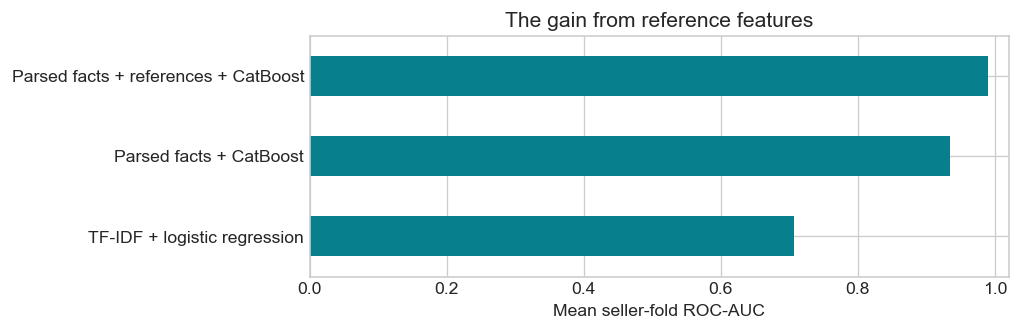

In [13]:
summary = pd.Series({
    "Mean fold ROC-AUC": scores['ROC-AUC'].mean(),
    "Fold standard deviation": scores['ROC-AUC'].std(ddof=0),
    "Pooled OOF ROC-AUC": roc_auc_score(y, oof),
    "OOF Average Precision": average_precision_score(y, oof),
})
display(summary.to_frame("score").round(6))

comparison = []
research_path = ROOT / "analysis/research_seed_42.json"
if research_path.exists():
    saved = json.loads(research_path.read_text(encoding="utf-8"))
    comparison += [
        {"approach": "TF-IDF + logistic regression", "mean_fold_auc": saved['provided_baseline']['mean_auc'],
         "source": "Saved research run"},
        {"approach": "Parsed facts + CatBoost", "mean_fold_auc": saved['parsed']['mean_auc'],
         "source": "Saved research run"},
    ]
comparison.append({"approach": "Parsed facts + references + CatBoost",
                   "mean_fold_auc": scores['ROC-AUC'].mean(), "source": "Executed in this notebook"})
comparison = pd.DataFrame(comparison)
display(comparison.round(6))
ax = comparison.plot.barh(x="approach", y="mean_fold_auc", legend=False, color=TEAL, figsize=(9, 3))
ax.set(xlabel="Mean seller-fold ROC-AUC", ylabel="", xlim=(0, 1.02), title="The gain from reference features")
plt.tight_layout()
plt.show()

## 8. See what the model uses

We average CatBoost's normalized feature importance across folds. The values sum to about 100.
The error bars show how importance varies between folds.

Importance describes how the fitted models use their inputs. A feature with importance 34 does not
account for 34% of accuracy, and correlated features can share importance. It does not establish cause.

,feature,mean_importance,std_importance
33,category_surprisal,33.760,1.723
32,shipping_weight_kg_abs_residual,18.680,0.692
29,price_pln_abs_residual,18.523,0.676
11,quantity_difference,17.521,0.750
8,desc_quantity,1.976,0.425
16,description_length,1.628,0.294
31,shipping_weight_kg_residual,0.854,0.142
0,declared_category,0.818,0.126
28,price_pln_residual,0.686,0.140
25,shipping_weight_kg_per_declared_item,0.504,0.125


Importance total: 100.000000


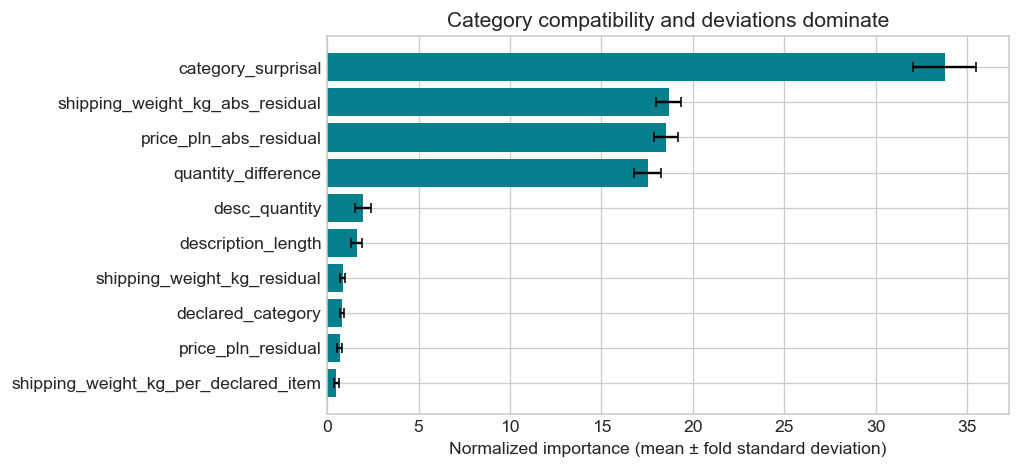

In [14]:
feature_names = pd.concat([fit_x, fit_ref], axis=1).columns
importance_table = pd.DataFrame({
    "feature": feature_names,
    "mean_importance": np.mean(importance, axis=0),
    "std_importance": np.std(importance, axis=0),
}).sort_values("mean_importance", ascending=False)
display(importance_table.head(10).round(3))
print(f"Importance total: {importance_table.mean_importance.sum():.6f}")
top = importance_table.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.barh(top.feature, top.mean_importance, xerr=top.std_importance, color=TEAL, capsize=3)
ax.set(xlabel="Normalized importance (mean ± fold standard deviation)",
       title="Category compatibility and deviations dominate")
plt.tight_layout()
plt.show()

Numeric deviations are evidence, not complete labels. A corrupted row can have perfectly normal price
and weight if its injected error affects category or quantity. Some target-0 rows also have unusual values.
The classifier combines the signals rather than using one global outlier threshold.

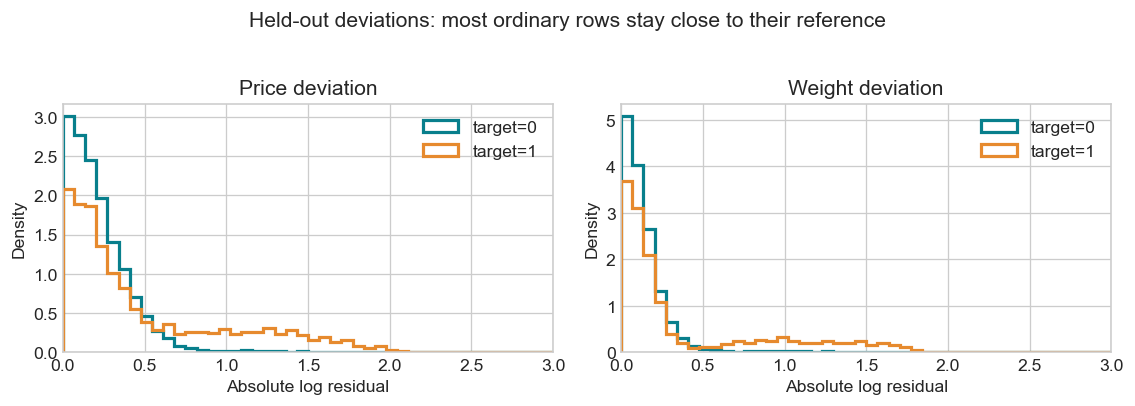

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, column, title in zip(axes,
    ["price_pln_abs_residual", "shipping_weight_kg_abs_residual"], ["Price deviation", "Weight deviation"]):
    for label, color in [(0, TEAL), (1, ORANGE)]:
        values = reference_oof.loc[y == label, column].dropna()
        ax.hist(values, bins=np.linspace(0, 3, 45), density=True, histtype="step",
                linewidth=2, color=color, label=f"target={label}")
    ax.set(title=title, xlabel="Absolute log residual", ylabel="Density", xlim=(0, 3))
    ax.legend()
fig.suptitle("Held-out deviations: most ordinary rows stay close to their reference", y=1.03)
plt.tight_layout()
plt.show()

## 9. Check the weak spots

A strong overall score can hide a weak subgroup. Product identity currently comes from the description.
When descriptions are missing, that identity is unknown and reference estimates become much less specific.
The table below compares these two groups using their held-out predictions.

This is the main limitation of the current implementation. Recovering product identity from titles,
including synonym handling, is the next targeted improvement.

In [16]:
subgroups = []
for missing in [False, True]:
    mask = train.description.isna().to_numpy() == missing
    subgroups.append({"description": "missing" if missing else "present",
                      "listings": int(mask.sum()), "positives": int(y[mask].sum()),
                      "ROC-AUC": roc_auc_score(y[mask], oof[mask]),
                      "Average Precision": average_precision_score(y[mask], oof[mask])})
display(pd.DataFrame(subgroups).round(4))

# Inspect a few errors instead of relying only on aggregate scores.
review = train[["id", "title", "declared_category", "target"]].copy()
review["prediction"] = oof
review["product"] = X['product']
review["error_score"] = np.where(y == 1, 1 - oof, oof)
display(review.sort_values("error_score", ascending=False).head(6).round(4))

,description,listings,positives,ROC-AUC,Average Precision
0,present,15320,2619,0.9921,0.9856
1,missing,680,102,0.7015,0.3881


,id,title,declared_category,target,prediction,product,error_score
3782,OFR_138318936,running belt — 1 units — Aste A183,sport,1,0.0030,jogging waist pouch,0.9970
8966,OFR_581300221,Velto D764: compact instrument cable (pack of one),music,1,0.0033,electric guitar connection lead,0.9967
15087,OFR_467358709,Aster B798: large plant pot (pack of three),garden,1,0.0036,flower growing container,0.9964
15586,OFR_108502813,language worbook — 1 units — Mira F852,books,1,0.0037,english practice volume,0.9963
6676,OFR_584208408,TENSO D149: STANDARD RESISTANCE BAND (1-PACK),sport,1,0.0037,elastic workout loop,0.9963
13324,OFR_813406107,NaN,audio,1,0.0037,microphone stand,0.9963


We also check whether predicted probabilities resemble observed frequencies. Ranking well does not
guarantee calibrated probabilities. Each point below groups predictions into a probability bin;
groups close to the diagonal are better calibrated. Some bins have few examples, so read the counts too.
This report does not optimize a threshold or fit a calibration model on the held-out labels.

,bin,listings,mean_prediction,positive_fraction
0,0,12794,0.009,0.008
1,1,348,0.140,0.138
2,2,170,0.244,0.259
3,3,108,0.342,0.306
4,4,59,0.448,0.424
5,5,51,0.547,0.667
6,6,43,0.656,0.674
7,7,60,0.748,0.800
8,8,95,0.861,0.916
9,9,2272,0.986,0.997


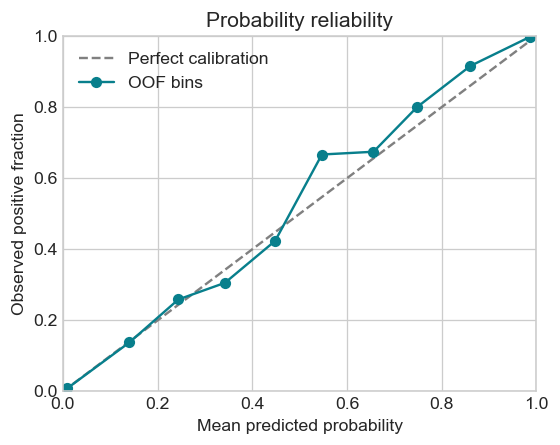

In [17]:
calibration = pd.DataFrame({"prediction": oof, "target": y,
                            "bin": np.minimum((oof * 10).astype(int), 9)})
calibration = calibration.groupby("bin").agg(
    listings=("target", "size"), mean_prediction=("prediction", "mean"),
    positive_fraction=("target", "mean")).reset_index()
display(calibration.round(3))
fig, ax = plt.subplots(figsize=(5, 4))
ax.plot([0, 1], [0, 1], "--", color="gray", label="Perfect calibration")
ax.plot(calibration.mean_prediction, calibration.positive_fraction, "o-", color=TEAL, label="OOF bins")
ax.set(xlabel="Mean predicted probability", ylabel="Observed positive fraction",
       title="Probability reliability", xlim=(0, 1), ylim=(0, 1))
ax.legend()
plt.tight_layout()
plt.show()

## 10. Create the submission and retain the evidence

Each test probability is the average of five models. The output keeps the exact ID order from the sample
submission and contains `id,target`. We check that probabilities are finite and between 0 and 1.

This notebook writes a submission, OOF predictions, feature importance, and a short metrics record to
its own output folder. It does not upload anything to Kaggle. The full project pipeline additionally
saves all five model bundles and their reference estimators for later prediction without retraining.

In [18]:
submission = pd.DataFrame({"id": test.id, "target": test_probability})
assert submission.id.tolist() == sample.id.tolist()
assert np.isfinite(submission.target).all() and submission.target.between(0, 1).all()

OUT = ROOT / "outputs/notebook_walkthrough"
OUT.mkdir(parents=True, exist_ok=True)
submission.to_csv(OUT / "submission.csv", index=False)
pd.DataFrame({"id": train.id, "seller_id": train.seller_id, "target": y,
              "prediction": oof, "fold": fold_id + 1}).to_csv(OUT / "oof.csv", index=False)
importance_table.to_csv(OUT / "feature_importance.csv", index=False)
metrics = {
    "summary": summary.to_dict(), "folds": scores.to_dict("records"),
    "subgroups": subgroups, "seed": SEED, "outer_folds": N_FOLDS, "inner_folds": INNER_FOLDS,
    "versions": {name: version(name) for name in ["numpy", "pandas", "scikit-learn", "catboost"]},
    "input_sha256": {name: hashlib.sha256((DATA / name).read_bytes()).hexdigest()
                     for name in ["train.csv", "test.csv", "sample_submission.csv"]},
}
(OUT / "metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
display(submission.head())
print(f"Saved {len(submission):,} predictions to {OUT / 'submission.csv'}")

,id,target
0,OFR_257241802,0.003486
1,OFR_374432657,0.004094
2,OFR_779902838,0.004593
3,OFR_633003662,0.927274
4,OFR_236006399,0.994597


Saved 10,000 predictions to C:\Users\adilk\Desktop\PJATK\KOLO NAUKOWE\outputs\notebook_walkthrough\submission.csv


## What to say when walking the team through it

We first extract product facts from the listing text. Then we use training rows without injected errors
to learn the catalogue's normal category choices and expected prices and weights. We turn departures
from those expectations into features and let CatBoost combine them with quantity checks and the
original structured fields.

The key contribution is the **learned reference**, rather than a universal rule for what every product
must look like. Validation holds out entire sellers, with a second layer of seller splitting to prevent
the reference features from using a row's own label.

The results are local validation results, not a Kaggle score. The descriptions are synthetic and templated,
and future wording or unseen product families may behave differently. The missing-description subgroup
shows why we need to examine coverage and errors alongside the headline score.

## Related work and the full implementation

The research that informed the approach:

- [Amazon PatternRAG](https://www.amazon.science/publications/leveraging-product-catalog-patterns-for-multilingual-e-commerce-product-attribute-prediction): use similar catalogue entries to infer attributes.
- [Robust variational autoencoders for mixed-type data](https://proceedings.mlr.press/v108/eduardo20a.html): learn normal relationships and identify corrupted cells. Our implementation uses simpler regressions and a supervised classifier.

Project files:

- `../README.md` explains the full command-line pipeline.
- `../catalogue_quality/` contains input checks, saved models, prediction and detailed reporting.
- `../analysis/research_notes.md` records the earlier experiments and limitations.

To run the packaged implementation from the project folder, choose a fresh output name:

```powershell
python -m catalogue_quality train --output-dir outputs/team_run
```